# 6. From Toffolis to physical qubits and hours

Notebooks 02 to 05 give a Toffoli count and a number of logical qubits. A real machine has physical qubits that fail at some rate $p$. What code distance does a run need, how many physical qubits is that, and how long does it take? And where, in the end, does every number in an estimate come from?

In [1]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
from openfermion.resource_estimates.surface_code_compilation.physical_costing import cost_estimator

import qcost
from qcost.surface_code import footprint, logical_error_per_round

## The recipe

`footprint(logical_qubits, toffolis)` returns the code distance, the physical qubits and the hours. For the 100-spin Ising chain of notebook 00:

In [2]:
est = qcost.estimate(qcost.tfim(100), eps=0.01)
fp = footprint(est["logical qubits"], est["Toffolis"])
for k, v in fp.items():
    print(f"{k:22} {v:>14,.6g}")

distance                           25
physical qubits               438,816
data qubits                   348,816
factory qubits                 90,000
seconds per Toffoli         0.0001375
hours                        0.864398


## Three rules of thumb

1. **A logical qubit is a $d\times d$ patch** of data qubits with measurement qubits between them, about $2(d+1)^2$ physical qubits with spacing [Gidney and Ekerå, [arXiv:1905.09749](https://arxiv.org/abs/1905.09749), Sec. 2.14].
2. **Each patch fails per round** with probability
$$p_L = 0.1\,(100\,p)^{(d+1)/2}$$
at circuit-level physical error rate $p$ below the threshold of about 1% [Fowler and Gidney, [arXiv:1808.06709](https://arxiv.org/abs/1808.06709), Sec. XV; Litinski, [arXiv:1808.02892](https://arxiv.org/abs/1808.02892), Eq. 10]. Every 2 added to $d$ divides it by $1/(100p)$:

In [3]:
print(f"{'d':>3} {'p = 1e-3':>10} {'p = 1e-4':>10} {'qubits per patch':>17}")
for d in (11, 15, 21, 25, 31):
    print(f"{d:3d} {logical_error_per_round(1e-3, d):10.0e} {logical_error_per_round(1e-4, d):10.0e} {2*(d+1)**2:17,d}")

  d   p = 1e-3   p = 1e-4  qubits per patch
 11      1e-07      1e-13               288
 15      1e-09      1e-17               512
 21      1e-12      1e-23               968
 25      1e-14      1e-27             1,352
 31      1e-17      1e-33             2,048


3. **Toffolis come from a factory.** The CCZ factory of Gidney and Fowler [[arXiv:1812.01238](https://arxiv.org/abs/1812.01238)] occupies $12d\times 6d$ and makes one CCZ state every $5.5d$ rounds; with 1 μs rounds and $d = 31$ that is 170 μs per Toffoli [as used by Babbush et al., [arXiv:2011.04149](https://arxiv.org/abs/2011.04149), Eq. 6]. Clifford gates are fast by comparison, so the run lasts (Toffolis) × (time per Toffoli).

## Choosing the distance

The run lasts $R = 5.5\,d \times$ Toffolis rounds, on $Q$ patches (the logical qubits plus half again for routing). The expected number of logical failures is $Q\,R\,p_L(d)$; take the smallest odd $d$ that keeps it below 1%:

In [4]:
Q = int(np.ceil(est["logical qubits"] * 1.5))
for d in range(19, 29, 2):
    R = 5.5 * d * est["Toffolis"]
    print(f"d = {d}: expected logical failures {Q * R * logical_error_per_round(1e-3, d):8.2e}")

d = 19: expected logical failures 6.10e+00
d = 21: expected logical failures 6.74e-01
d = 23: expected logical failures 7.39e-02
d = 25: expected logical failures 8.03e-03
d = 27: expected logical failures 8.67e-04


$d = 25$: the distance grows only like the logarithm of the run's size, which is why a $10^{10}$-Toffoli run (FeMoco) needs $d = 35$ rather than something astronomical.

## A cross-check

OpenFermion's `cost_estimator` does the same with more care: it searches over factory designs (two-level distillation, error per CCZ state), uses four factories in parallel, and accepts a 10% failure chance. Same inputs, both models:

In [5]:
cases = {"TFIM, 100 spins": (est["logical qubits"], est["Toffolis"]), "FeMoco (Lee et al.)": (3725, 10_073_183_463)}
print(f"{'':22}{'ours: qubits':>14}{'hours':>8}{'d':>4}   {'OpenFermion: qubits':>20}{'hours':>8}{'d':>4}")
for name, (q, t) in cases.items():
    ours = footprint(q, t)
    four = footprint(q, t, factories=4, budget=0.1)
    best, params = cost_estimator(q, t)
    hours = best.duration / datetime.timedelta(hours=1)
    print(f"{name:22}{ours['physical qubits']:14,}{ours['hours']:8.1f}{ours['distance']:4d}"
          f"   {best.physical_qubit_count:20,}{hours:8.1f}{params.logical_data_qubit_distance:4d}")
    print(f"{'  ours, 4 factories, 10%':22}{four['physical qubits']:14,}{four['hours']:8.1f}{four['distance']:4d}")

                        ours: qubits   hours   d    OpenFermion: qubits   hours   d
TFIM, 100 spins              438,816     0.9  25                850,176     0.2  23
  ours, 4 factories, 10%       601,920     0.2  23
FeMoco (Lee et al.)       14,660,496   538.6  35             12,196,864    94.4  31
  ours, 4 factories, 10%    11,997,760   119.3  31


With the same choices (four factories, 10% failure), the two models agree on the order of magnitude of both qubits and hours. The remaining differences are in the factory (OpenFermion picks the smallest distillation distances that meet the error target; ours uses the data distance) and the time per Toffoli.

## The full trace of one estimate

Every number in the TFIM estimate, where it comes from:

In [6]:
H = qcost.tfim(100)
e = qcost.estimate(H, eps=0.01)
trace = [
    ("terms L", e["terms L"], "count of Pauli words", "the Hamiltonian"),
    ("lambda", e["lambda"], "sum |c_l|", "notebook 04"),
    ("keep bits mu", e["keep bits mu"], "ceil log2(2 sqrt2 lambda / eps)", "1805.03662 Eq. 36"),
    ("SELECT", e["  step: SELECT"], "L - 1 (unary iteration)", "1805.03662 Fig. 7; nb 03"),
    ("PREPARE", e["  step: PREPARE"], "uniform + (L-1) + mu + log L", "1805.03662 Fig. 11; nb 04"),
    ("PREPARE inverse", e["  step: PREPARE inverse"], "same as PREPARE", "nb 04"),
    ("reflection", e["  step: reflection"], "log L + mu (n controls: n-1, + 1 control)", "1709.06648 p. 5"),
    ("Toffolis per step", e["Toffolis per walk step"], "sum of the four above", ""),
    ("walk calls", e["walk calls"], "ceil(pi lambda / (2 eps))", "2011.03494 Eq. 45"),
    ("Toffolis", e["Toffolis"], "calls x per step", ""),
    ("logical qubits", e["logical qubits"], "system + index + alias + flags + phase", "nb 04"),
    ("distance", e["distance"], "Q R p_L(d) < 1%", "1808.06709 Sec. XV"),
    ("physical qubits", e["physical qubits"], "1.5 Q 2(d+1)^2 + factory 2 (12d)(6d)", "1905.09749; 1812.01238"),
    ("hours", e["hours"], "Toffolis x 5.5 d x 1 us", "1812.01238"),
]
for name, value, formula, source in trace:
    print(f"{name:18} {value:>14,.6g}   {formula:42} {source}")

terms L                       199   count of Pauli words                       the Hamiltonian
lambda                        199   sum |c_l|                                  notebook 04
keep bits mu                   16   ceil log2(2 sqrt2 lambda / eps)            1805.03662 Eq. 36
SELECT                        198   L - 1 (unary iteration)                    1805.03662 Fig. 7; nb 03
PREPARE                       251   uniform + (L-1) + mu + log L               1805.03662 Fig. 11; nb 04
PREPARE inverse               251   same as PREPARE                            nb 04
reflection                     24   log L + mu (n controls: n-1, + 1 control)  1709.06648 p. 5
Toffolis per step             724   sum of the four above                      
walk calls                 31,259   ceil(pi lambda / (2 eps))                  2011.03494 Eq. 45
Toffolis              2.26315e+07   calls x per step                           
logical qubits                172   system + index + alias + flags + ph

## How it grows

Live, from 10 to 1000 spins (seconds):

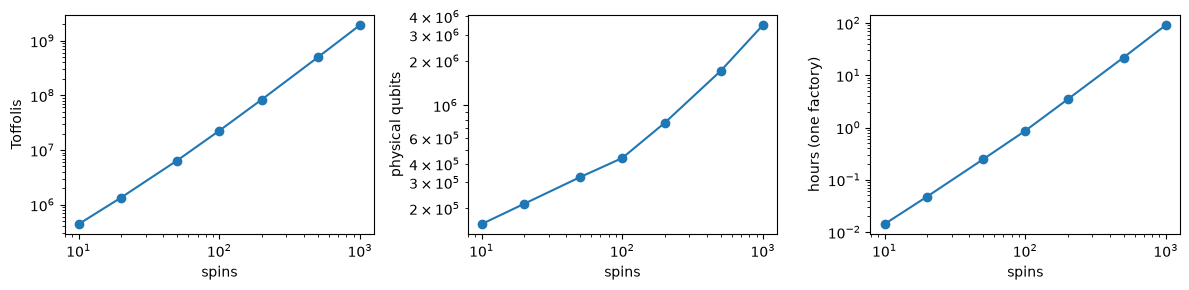

In [7]:
ns = np.array([10, 20, 50, 100, 200, 500, 1000])
rows = [qcost.estimate(qcost.tfim(n), eps=0.01) for n in ns]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].loglog(ns, [r["Toffolis"] for r in rows], "o-")
ax[0].set_ylabel("Toffolis")
ax[1].loglog(ns, [r["physical qubits"] for r in rows], "o-")
ax[1].set_ylabel("physical qubits")
ax[2].loglog(ns, [r["hours"] for r in rows], "o-")
ax[2].set_ylabel("hours (one factory)")
for a in ax:
    a.set_xlabel("spins")
plt.tight_layout()

Physical qubits grow about linearly in $n$, the run time about as $n^2$. The DMRG notebooks of [dmrg-from-scratch](https://github.com/liukeLyu/dmrg-from-scratch) (13 and 14) put this kind of quantum price next to the classical one, for frustrated magnets on cylinders.

## Exercises

1. Redo the 100-spin estimate at $p = 10^{-4}$. Which changes more, the distance or the hours?
2. With 10 factories in parallel, how much faster is the FeMoco run, and how many more physical qubits does it need?
3. The error budget here splits $\epsilon$ entirely to phase estimation and sets $\mu$ separately. Lee et al. split 1.6 mHa into 1.0 for phase estimation and 0.6 for the factorization [arXiv:2011.03494, Eq. 25]. Write the 100-spin estimate with $\epsilon_\text{PE} = 0.008$ and see what changes.